In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:

data = sc.read_h5ad("../../input/exp2_test_day12_cluster_0.h5ad")
# data = sc.read_h5ad("../input/plant_all_days.h5ad")
# print(print(adata[:5, :10].to_df()))
# Convert to dense numpy array regardless of sparse/dense format

X = data.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)

print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(406, 39337)
15970822
15970822
min: 0.0
max: 66.0
mean: 0.054928478
below 0: 0
below 0: 0.0


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/scipy/sparse/_compressed.py:291: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using < is inefficient, try using >= instead.
  warn(bad_scalar_msg, SparseEfficiencyWarning)


below 0.1: 15353269
below 0.1: 0.9613324223386874


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3508: SparseEfficiencyWarning: Comparing a sparse matrix with 0 using == is inefficient, try using != instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


equals 0: 15353269
equals 0: 0.9613324223386874
below 18: 15970197
below 18: 0.9999608661345045
nan: 0


In [3]:
import scipy.sparse as sp
import numpy as np
for i in range(15):
    if i ==11:
        continue
    adata = sc.read_h5ad(f"../experiments/plants_experiment2_predict_day21_cluster{i}_flexible_cells/interception_predict_to_day_21.h5ad")
    # print(adata[:5, :10].to_df())
    X = adata.X
    # print(X.size)

    # print(X.shape)
    # print(X.shape[0] * X.shape[1])
    # total = X.shape[0] * X.shape[1]
    # print("min:", np.min(X))
    # print("max:", np.max(X))
    # print("mean:", np.mean(X))
    if np.sum(X < 0) > 0:
        print("below 0:", np.sum(X < 0))
        print("below 0:", np.sum(X < 0)/total)
    # print("below 0.1:", np.sum(X < 0.1))
    # print("below 0.1:", np.sum(X < 0.1)/total)
    # print("equals 0:", np.sum(X == 0))
    # print("equals 0:", np.sum(X == 0)/total)
    # print("below 18:", np.sum(X < 18))
    # print("below 18:", np.sum(X < 18)/total)
    # nan_count = np.isnan(X.data).sum()
    # print("nan:", nan_count)


0 0.9550223282191661 0.9900976013248067
16.045822 20.540688
max 20.540688
cluster 0 done
1 0.9505261936458708 0.9801429795322731
4.113171 4.207502
max 4.207502
cluster 1 done
2 0.8423008656033268 0.9558843441983574
4.0395885 4.102275
max 4.102275
cluster 2 done
3 -0.8126087396241024 0.4613829902503605
2.8021085 3.7287495
max 3.7287495
cluster 3 done
4 0.77890175837583 0.9503324375878061
3.888295 4.1970644
max 4.1970644
cluster 4 done
5 0.5063004567689549 0.8310049015273304
4.300791 4.0165153
max 4.300791
cluster 5 done
6 -0.3512134853857476 0.5536238407836773
5.2361927 4.337413
max 5.2361927
cluster 6 done
7 0.9433860686669512 0.9863594228028136
9.89196 12.355805
max 12.355805
cluster 7 done
8 0.3860997925201337 0.735634287803257
3.5814261 4.1725388
max 4.1725388
cluster 8 done
9 0.826529028785554 0.9227369568248759
3.8092399 4.2183046
max 4.2183046
cluster 9 done
10 0.1522128083292532 0.6089997934698306
3.1239645 4.1481733
max 4.1481733
cluster 10 done
12 0.871281071314549 0.972183386

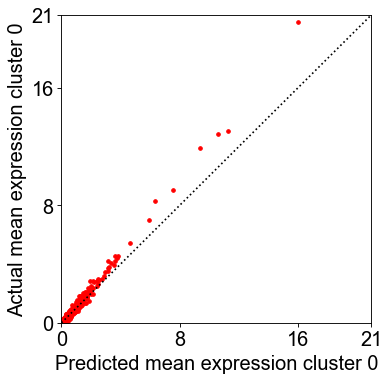

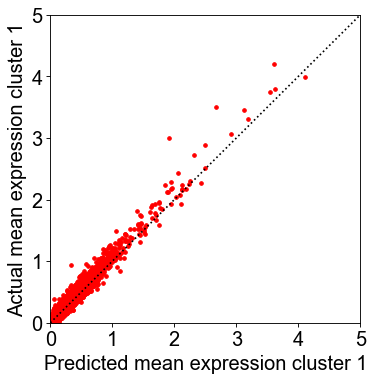

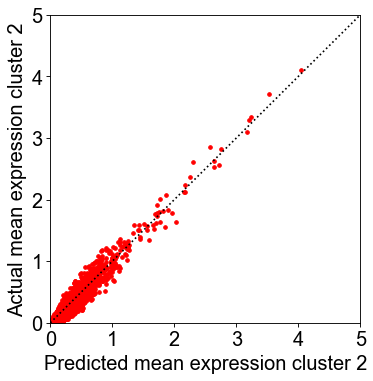

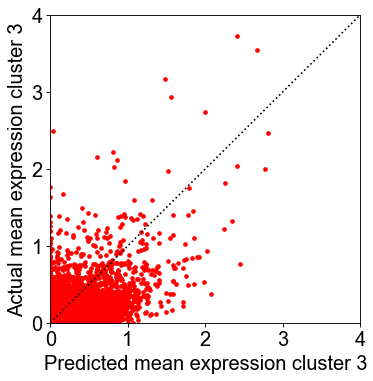

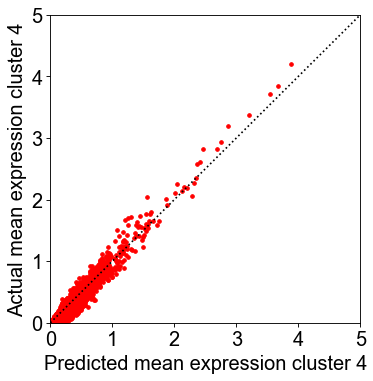

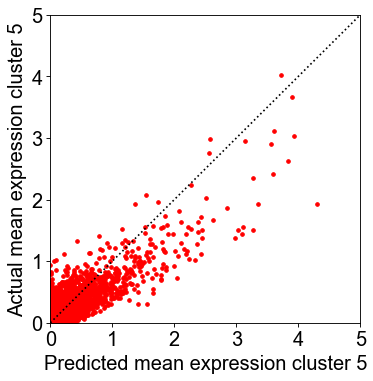

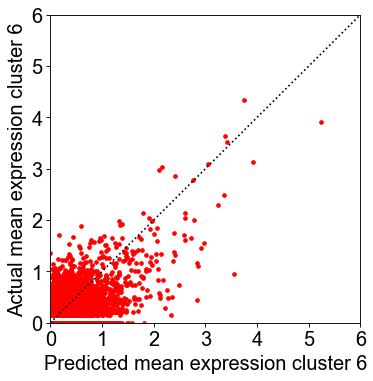

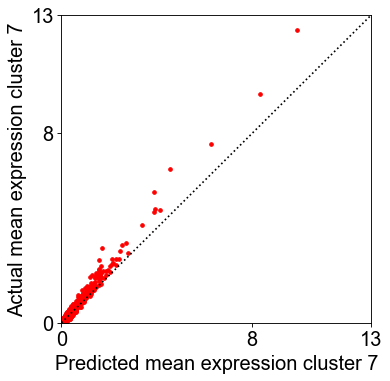

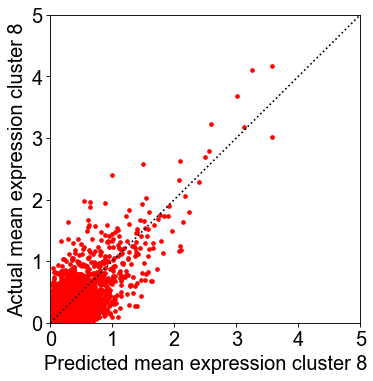

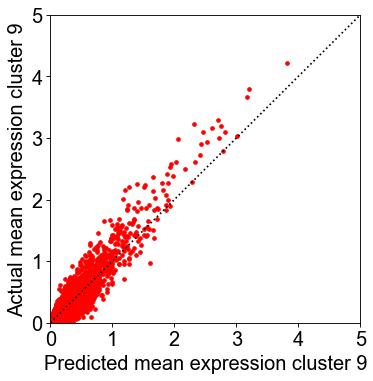

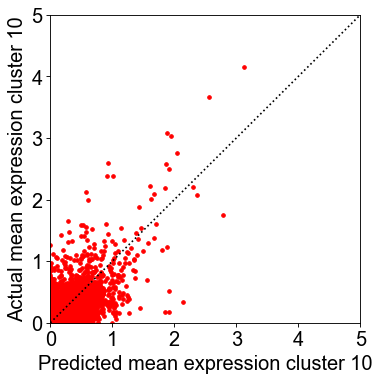

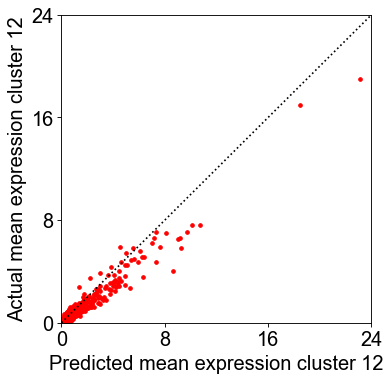

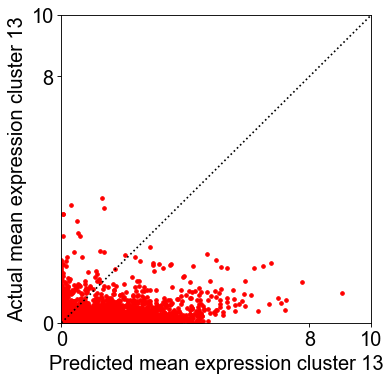

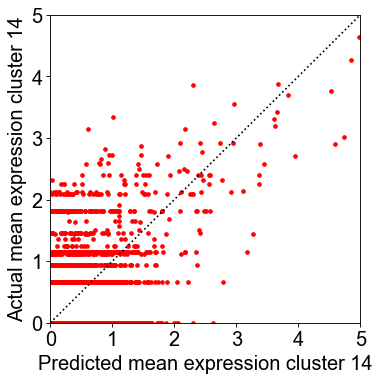

In [4]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
for i in range(15):
  if i ==11:
    continue
  real_data = sc.read_h5ad(f"../../input/exp2_test_day21_cluster_{i}.h5ad")
  predict_data = sc.read_h5ad(f"../experiments/plants_experiment2_predict_day21_cluster{i}_flexible_cells/interception_predict_to_day_21.h5ad")
  r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
  
  print(i, r2, pearsonr)
  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  r_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  pearsonr_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])


  pd.DataFrame(r_all).to_csv(os.path.join("our_method_plant_exp1_r_all.csv"))
  pd.DataFrame(pearsonr_all).to_csv(os.path.join("our_method_plant_exp1_pearsonr_all.csv"))

  fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
  plt.scatter(predict,
              real,
              s=10,
              c='red'
            )
  limit = np.ceil(max(np.max(predict), np.max(real)))
  print(np.max(predict),np.max(real))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    ticks = np.arange(0, limit + 1, 1)
  else:    
    ticks = np.arange(0, limit + 1, 8)
    
  ticks = np.append(ticks, limit)
  ticks = np.unique(ticks)
  plt.xticks(ticks)
  plt.yticks(ticks)
  print("max",max(np.max(predict), np.max(real)))

  plt.xlabel(f"Predicted mean expression cluster {i}")
  plt.ylabel(f"Actual mean expression cluster {i}")
  print(f"cluster {i} done")
  # fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")
  fig.savefig(os.path.join(f"pred_with_actual_exp2_flexible_cluster_{i}.pdf"), bbox_inches="tight")
  
# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')